# Demo introduction
In this demo you will work with a small environment built from open source software, similar to the building blocks used in Dell's data lakehouse and data processing offerings.

The demo includes:
- Apache Spark
- Trino
- Hive Metastore (HMS)
- PostgreSQL, as the backend database for HMS
- Apache Iceberg
- PowerScale S3, as the backend storage


Let's start by creating an Iceberg table with Spark. This writes the table's Iceberg metadata to PowerScale and registers its location in the Hive Metastore. We will explore each part as we walk through this notebook.


In [2]:
%%sql
CREATE NAMESPACE IF NOT EXISTS sales

++
||
++
++

In [3]:
%%sql
CREATE TABLE IF NOT EXISTS sales.orders (
    order_id    BIGINT,
    customer    STRING,
    amount      DOUBLE,
    order_date  DATE
) USING iceberg
PARTITIONED BY (months(order_date))
TBLPROPERTIES ('format-version' = '2')

++
||
++
++

In [4]:
%%sql
INSERT INTO sales.orders VALUES
  (1, 'alice', 20.0, DATE '2026-09-28'),
  (2, 'bob',   35.5, DATE '2026-10-02')

++
||
++
++

In [5]:
%%sql
SELECT * FROM sales.orders

order_id,customer,amount,order_date
1,alice,20.0,2026-09-28
2,bob,35.5,2026-10-02


Now let us read the created Iceberg Table using Trino 

In [6]:
import trino #need to import trino to access this notebook, as we are working with jupyter part of Spark container
import pandas as pd

conn = trino.dbapi.connect(
    host="trino",      # the Trino container's name on the Docker network
    port=8080,
    user="jupyter",    # any name works, there's no password
    catalog="iceberg",
    schema="sales",
)

def trino_sql(q):
    cur = conn.cursor()
    cur.execute(q)
    rows = cur.fetchall()
    cols = [c[0] for c in cur.description] if cur.description else []
    return pd.DataFrame(rows, columns=cols)

In [7]:
trino_sql("SHOW TABLES") #list of the tables inside sales namespace

,Table
0,orders


In [4]:
trino_sql("SELECT * FROM orders ORDER BY order_id")

,order_id,customer,amount,order_date
0,1,alice,20.0,2026-09-28
1,2,bob,35.5,2026-10-02


## HMS & Iceberg metadata exploration

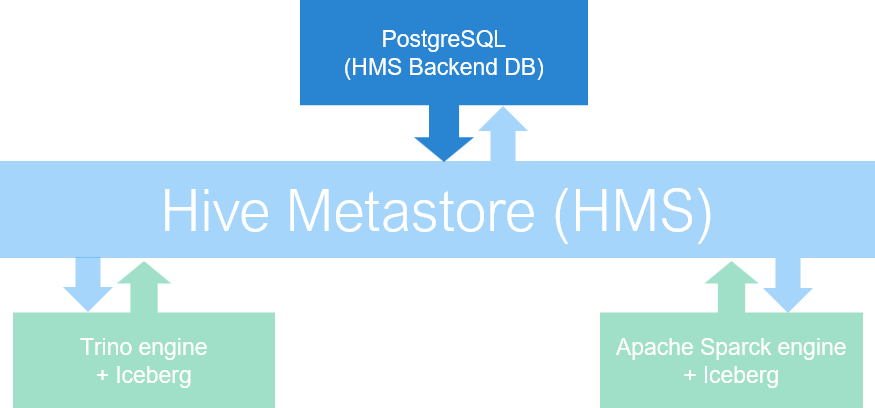

In this demo, the Hive Metastore is deployed as a centralized metastore for the whole environment. It serves as the catalog layer for the Iceberg tables, shared by Spark and Trino.

Spark is used for most of the steps below, because Jupyter runs inside the Spark container, so Spark is built into the notebook. It's worth noting that Trino can read the same metadata. Because both engines read the same files on PowerScale, the facts are identical: same snapshot IDs, same manifests, same data files. What differs is how each engine names and displays them.


Below is the setup used to explore the Iceberg metadata tree for `sales.orders`, created earlier with Spark SQL and read with Trino:


In [8]:
import json
from urllib.parse import urlparse
import pandas as pd
from pyarrow import fs

pd.set_option("display.max_colwidth", 120)
TABLE = "sales.orders" # the table to explore; change this to look at another table

def sql(q):
    return spark.sql(q).toPandas() # run Spark SQL and return the result as a pandas table

# PowerScale S3 client, same endpoint and keys as Spark
_ep = urlparse(spark.conf.get("spark.sql.catalog.iceberg.s3.endpoint"))
s3 = fs.S3FileSystem(endpoint_override=_ep.netloc, scheme=_ep.scheme, region="us-east-1")

def read_json(path):
    key = path.split("://", 1)[-1]          # s3a://bucket/key -> bucket/key
    with s3.open_input_stream(key) as f:
        return json.loads(f.read())

## How Iceberg finds the data: the three layers

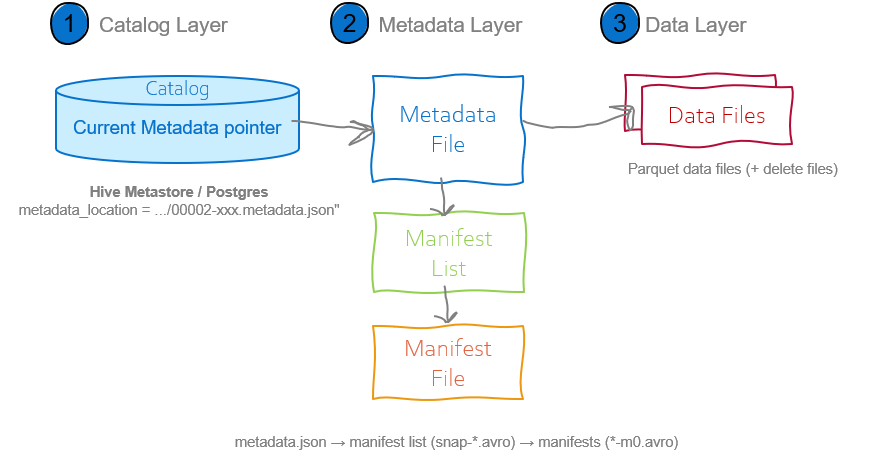

| Layer | What it holds | Where it lives |
|---|---|---|
| **Catalog** | The pointer to the current `metadata.json` | Hive Metastore, stored in Postgres |
| **Metadata** | Schema, partitions, snapshots, and the list of data files | PowerScale, `metadata/` folder |
| **Data** | The table's rows (Parquet) and delete files | PowerScale, `data/` folder |

## Catalog layer

The catalog layer is the phone book. It tells every engine (Spark, Trino) where the
table's latest `metadata.json` file is. It is a separate service that sits outside the
table's files. Here it is the Hive Metastore, which stores its records in a Postgres database.

The catalog also has a second job: every time a table changes, it switches the pointer
to the new `metadata.json` in a single step. This keeps the table safe when more than
one engine writes to it.

In this section we read the catalog's records straight from Postgres for `sales.orders`:

* **The pointer**: `metadata_location`, the path to the current `metadata.json` on PowerScale.
  This is the only value engines use to find the table.
* **The previous pointer**: `previous_metadata_location`, the file used before the last change. Useful for recovering the table if the latest commit goes wrong.
* **The table type**: `table_type = ICEBERG`, which tells engines to read it as an Iceberg table.
* **Other key/value properties**: summary values Iceberg copies here, such as the
  current snapshot ID and record counts.
* **Location and input/output formats** (from the `SDS` table): copies kept so older
  Hive tools can see the table. Spark and Trino do not use them.

**How the pointer query works**

`TABLE_PARAMS` stores properties by table number (`TBL_ID`), not by name.
So we join three tables to find the right rows:

DBS ("sales") → TBLS ("orders", gives TBL_ID) → TABLE_PARAMS (properties for that TBL_ID)

Result: `metadata_location`, `previous_metadata_location`, `table_type`


In [6]:
# joining multiple tables 
q = '''SELECT p."PARAM_KEY" AS key, p."PARAM_VALUE" AS value
       FROM "TBLS" t
       JOIN "DBS" d          ON t."DB_ID"  = d."DB_ID"
       JOIN "TABLE_PARAMS" p ON p."TBL_ID" = t."TBL_ID"
       WHERE d."NAME" = 'sales' AND t."TBL_NAME" = 'orders'
         AND p."PARAM_KEY" IN ('table_type', 'metadata_location', 'previous_metadata_location')'''  
#read posgresql to spark as jdbc 
spark.read.jdbc("jdbc:postgresql://postgres:5432/hive_metastore", f"({q}) AS t",
                properties={"user": "hive", "password": "password",
                            "driver": "org.postgresql.Driver"}).toPandas()

,key,value
0,metadata_location,s3a://warehouse/hive/external/sales.db/orders/metadata/00001-a9bda561-ade1-4a13-9d95-2771b8b8c609.metadata.json
1,table_type,ICEBERG
2,previous_metadata_location,s3a://warehouse/hive/external/sales.db/orders/metadata/00000-4ea40cdc-c0b9-4e90-abb0-9c167bb3b8f6.metadata.json


## Metadata layer

The metadata layer describes the table: its columns, how it is partitioned, its history of snapshots, and which data files belong to each snapshot.
These files are stored on the PowerScale cluster, in the table's `metadata/` folder.

It is made of three kinds of files, each one pointing to the next:

| File | What it holds |
|---|---|
| `*.metadata.json` | Schema, partitioning, and the list of snapshots. A new one is written on every change. |
| Manifest list (`snap-*.avro`) | One per snapshot. Lists the manifests that make up that snapshot. |
| Manifest (`*-m0.avro`) | Lists the data files, with their row counts and column stats. |



### A look at every version of metadata.json

`metadata_log_entries` lists every `metadata.json` the table has had, one per change:

* **timestamp**: when that version was written
* **file**: the path to that `metadata.json` on PowerScale
* **latest_snapshot_id**: the snapshot that was current in that version.
  Empty for the first version (the table was just created, with no data yet),
  and repeated when only the schema changed.

Below, Spark SQL reads `metadata_log_entries` to list every `metadata.json` version.

In [7]:
sql(f"SELECT timestamp, file, latest_snapshot_id FROM {TABLE}.metadata_log_entries ORDER BY timestamp")

,timestamp,file,latest_snapshot_id
0,2026-10-10 19:42:34.617,s3a://warehouse/hive/external/sales.db/orders/metadata/00000-4ea40cdc-c0b9-4e90-abb0-9c167bb3b8f6.metadata.json,NaN
1,2026-10-10 19:48:25.415,s3a://warehouse/hive/external/sales.db/orders/metadata/00001-a9bda561-ade1-4a13-9d95-2771b8b8c609.metadata.json,3.588353e+18


### A look inside the metadata.json

This cell finds the table's current `metadata.json` file, opens it straight from PowerScale, and prints the main facts written inside it: format version, table UUID, location, and the current schema, partition spec and snapshot IDs.

It first asks Spark for the list of every `metadata.json` version (`metadata_log_entries`) and keeps only the newest one, which is the current version.


In [8]:
current = sql(f"SELECT file FROM {TABLE}.metadata_log_entries ORDER BY timestamp DESC LIMIT 1").iloc[0, 0]
meta = read_json(current) # download the file from PowerScale and parse the JSON

for k in ["format-version", "table-uuid", "location", "current-schema-id",
          "default-spec-id", "current-snapshot-id", "last-sequence-number"]:
    print(f"{k:22}: {meta.get(k)}") # pad key names to 22 characters so the values line up

format-version        : 2
table-uuid            : a66fa108-977e-4dd2-9cd1-957b52ab93ac
location              : s3a://warehouse/hive/external/sales.db/orders
current-schema-id     : 0
default-spec-id       : 0
current-snapshot-id   : 3588352512367642692
last-sequence-number  : 1


In [ ]:
# reading the schema and partition spec, as stored in the file
print(json.dumps(meta["schemas"][-1], indent=2))
print(json.dumps(meta["partition-specs"], indent=2))

{
  "type": "struct",
  "schema-id": 0,
  "fields": [
    {
      "id": 1,
      "name": "order_id",
      "required": false,
      "type": "long"
    },
    {
      "id": 2,
      "name": "customer",
      "required": false,
      "type": "string"
    },
    {
      "id": 3,
      "name": "amount",
      "required": false,
      "type": "double"
    },
    {
      "id": 4,
      "name": "order_date",
      "required": false,
      "type": "date"
    }
  ]
}
[
  {
    "spec-id": 0,
    "fields": [
      {
        "name": "order_date_month",
        "transform": "month",
        "source-id": 4,
        "field-id": 1000
      }
    ]
  }
]


### A look into the snapshot details

A snapshot is the full state of the table at one point in time. A new snapshot is
created every time data changes, for example on each `INSERT`, `DELETE` or `MERGE`.

Each snapshot points to exactly one **manifest list** (`snap-*.avro`), the file that
lists the manifests making up that version of the table.

Below, Spark SQL reads the `snapshots` metadata table to show each snapshot and its manifest list:

| Column | Meaning |
|---|---|
| `committed_at` | When the snapshot was created |
| `snapshot_id` | The snapshot's unique ID |
| `parent_id` | The snapshot it was built on (empty for the first one) |
| `operation` | What kind of change created it: `append`, `overwrite`, `delete` |
| `added_records` | How many rows that change added |
| `manifest_list` | The path to this snapshot's `snap-*.avro` file on PowerScale |

In [10]:
sql(f"""SELECT committed_at, snapshot_id, parent_id, operation,
               summary['added-records'] AS added_records, manifest_list
        FROM {TABLE}.snapshots ORDER BY committed_at""")

,committed_at,snapshot_id,parent_id,operation,added_records,manifest_list
0,2026-10-10 19:48:25.415,3588352512367642692,NaN,append,2,s3a://warehouse/hive/external/sales.db/orders/metadata/snap-3588352512367642692-1-0da7b9b8-2281-45aa-a9b4-75576b1e13...


### A look into the manifests

Below, Spark SQL reads the `manifests` metadata table: the contents of the current snapshot's manifest list.


In [11]:
sql(f"""SELECT path, added_snapshot_id, added_data_files_count,
               existing_data_files_count, deleted_data_files_count
        FROM {TABLE}.manifests""")

,path,added_snapshot_id,added_data_files_count,existing_data_files_count,deleted_data_files_count
0,s3a://warehouse/hive/external/sales.db/orders/metadata/0da7b9b8-2281-45aa-a9b4-75576b1e1318-m0.avro,3588352512367642692,2,0,0


## Data layer

The data layer holds the table's actual rows, stored on PowerScale in the table's `data/` folder.

* **Data files**: the rows themselves, in Parquet by default (ORC and Avro are also supported).
* **Delete files**: small files that mark rows as deleted without rewriting the data files.
  They only appear when the table uses `format-version 2` with `'write.delete.mode' = 'merge-on-read'`.
  With the default mode (copy-on-write), a `DELETE` rewrites the affected data files instead.

### A look into the data files

The `files` metadata table lists every data file in the current snapshot. Spark builds it from
the **manifests**, so it describes the files without opening them:

| Column | Meaning |
|---|---|
| `content` | `0` = data file, `1` = position delete file, `2` = equality delete file |
| `file_path` | Where the file is on PowerScale |
| `partition` | Which partition the file belongs to (here, the month of `order_date`) |
| `record_count` | How many rows the file holds |
| `file_size_in_bytes` | The file's size |
| `amount_stats` | Stats for the `amount` column: min, max, null count and more |

The column stats let Spark and Trino skip whole files. For example, a query for
`amount > 100` never opens a file whose maximum `amount` is 50.

In [12]:
sql(f"""SELECT content, file_path, partition, record_count, file_size_in_bytes,
               readable_metrics.amount AS amount_stats
        FROM {TABLE}.files""")

,file_path,partition,record_count,file_size_in_bytes,amount_stats
0,s3a://warehouse/hive/external/sales.db/orders/data/order_date_month=2026-09/00000-2-d5ee36d7-31f9-41ed-9fc0-7248c004...,"(680,)",1,1200,"(43, 1, 0, 0, 20.0, 20.0)"
1,s3a://warehouse/hive/external/sales.db/orders/data/order_date_month=2026-10/00000-2-d5ee36d7-31f9-41ed-9fc0-7248c004...,"(681,)",1,1186,"(43, 1, 0, 0, 35.5, 35.5)"


### A look into partitions and history 

Summaries built from the manifests and the snapshot log.


In [14]:
sql(f"SELECT partition, record_count, file_count FROM {TABLE}.partitions")

,partition,record_count,file_count
0,"(680,)",1,1
1,"(681,)",1,1


In [15]:
sql(f"SELECT made_current_at, snapshot_id, is_current_ancestor FROM {TABLE}.history")

,made_current_at,snapshot_id,is_current_ancestor
0,2026-10-10 19:48:25.415,3588352512367642692,True
